# TRUSTSR Lab 01 — Memory Poisoning and Contamination Graph

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Lab status:** Research prototype / synthetic simulation  
**Notebook version:** 0.1.0

## Research objective

Demonstrate how a poisoned memory item can influence downstream agent states in a directed dependency graph, then identify the descendants of that memory as **potentially contaminated**.

This notebook is a controlled simulation. It does **not** implement a complete agent, prove causal relationships in real systems, validate TRUSTSR's formal guarantees, or establish performance claims from the monograph.

## Hypothesis

If state-dependency edges correctly represent influence, then graph reachability from a known poisoned node can identify the states that may depend on that node.

## Important terminology

- **Poisoned node:** A node deliberately marked as compromised in this synthetic scenario.
- **Descendant / potentially contaminated state:** A node reachable from the poisoned node by following directed dependency edges.
- **Ground truth:** The scenario's explicitly declared poison source and synthetic dependency graph. This is known by construction, not inferred from real-world observations.
- **Measured result:** A value computed by executing this notebook. It is a measurement of this simulation only—not evidence of real-agent effectiveness.

## Reproducibility

Run the notebook from top to bottom in a fresh Google Colab runtime. All scenario data is generated in the notebook; no external files or API keys are required.

## 1. Environment setup

The notebook uses common Python libraries. Colab usually includes them already; the installation cell makes the environment setup explicit.

In [1]:
%pip -q install networkx pandas matplotlib

In [2]:
import sys
import platform
import random
from datetime import datetime, timezone

import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

SEED = 20261010
random.seed(SEED)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NetworkX:", nx.__version__)
print("Pandas:", pd.__version__)
print("Random seed:", SEED)
print("Execution timestamp (UTC):", datetime.now(timezone.utc).isoformat())

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
NetworkX: 3.6.1
Pandas: 3.0.2
Random seed: 20261010
Execution timestamp (UTC): 2026-10-11T10:26:31.800662+00:00


## 2. Define the synthetic scenario

We create one memory-poisoning event and a small sequence of dependent states. The edge direction is **source → dependent state**: an edge `A → B` means that, in this scenario, state B used or depended on state A.

This is an explicit modeling assumption. A real system would need reliable event provenance to justify each edge.

In [3]:
# Synthetic states: IDs are stable so that outputs are reproducible.
states = [
    {"id": "M1", "label": "Trusted project requirement", "kind": "memory", "status": "trusted"},
    {"id": "M2", "label": "Poisoned memory: unsafe instruction", "kind": "memory", "status": "poisoned"},
    {"id": "D1", "label": "Planning decision A", "kind": "decision", "status": "normal"},
    {"id": "D2", "label": "Planning decision B", "kind": "decision", "status": "normal"},
    {"id": "P1", "label": "Execution plan A", "kind": "plan", "status": "normal"},
    {"id": "P2", "label": "Execution plan B", "kind": "plan", "status": "normal"},
    {"id": "A1", "label": "Derived action record", "kind": "action", "status": "normal"},
    {"id": "S1", "label": "Independent status note", "kind": "state", "status": "normal"},
]

# Each pair is (source, dependent). This graph is intentionally synthetic.
dependencies = [
    ("M1", "D1"),
    ("M2", "D1"),
    ("D1", "P1"),
    ("P1", "A1"),
    ("M2", "D2"),
    ("D2", "P2"),
    ("M1", "S1"),  # independent branch; no path from M2
]

state_df = pd.DataFrame(states)
edge_df = pd.DataFrame(dependencies, columns=["source", "dependent"])

print("State records:", len(state_df))
print("Dependency edges:", len(edge_df))
display(state_df)
display(edge_df)

State records: 8
Dependency edges: 7


   id                                label      kind    status
0  M1          Trusted project requirement    memory   trusted
1  M2  Poisoned memory: unsafe instruction    memory  poisoned
2  D1                  Planning decision A  decision    normal
3  D2                  Planning decision B  decision    normal
4  P1                     Execution plan A      plan    normal
5  P2                     Execution plan B      plan    normal
6  A1                Derived action record    action    normal
7  S1              Independent status note     state    normal

  source dependent
0     M1        D1
1     M2        D1
2     D1        P1
3     P1        A1
4     M2        D2
5     D2        P2
6     M1        S1

## 3. Build the Causal State Graph (CSG)

For this prototype, the CSG is represented as a directed graph. Nodes hold state metadata; edges record declared dependencies.

**Important limitation:** The graph does not discover causal dependencies automatically. The example assumes the declared edges are accurate.

In [4]:
G = nx.DiGraph()

for state in states:
    G.add_node(
        state["id"],
        label=state["label"],
        kind=state["kind"],
        initial_status=state["status"]
    )

G.add_edges_from(dependencies)

assert nx.is_directed_acyclic_graph(G), "This demonstration expects a directed acyclic graph."
assert "M2" in G, "Poison source must exist in the graph."

print("Graph created.")
print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Directed acyclic graph:", nx.is_directed_acyclic_graph(G))
print("Nodes:", list(G.nodes()))
print("Edges:", list(G.edges()))

Graph created.
Nodes: 8
Edges: 7
Directed acyclic graph: True
Nodes: ['M1', 'M2', 'D1', 'D2', 'P1', 'P2', 'A1', 'S1']
Edges: [('M1', 'D1'), ('M1', 'S1'), ('M2', 'D1'), ('M2', 'D2'), ('D1', 'P1'), ('D2', 'P2'), ('P1', 'A1')]


## 4. Visualize the graph before contamination analysis

The layout is for readability only. Node positions do not represent time, severity, or quantitative influence.

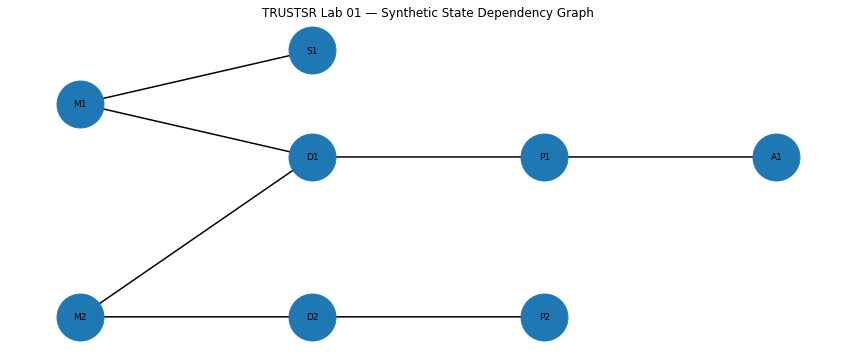

In [5]:
pos = {
    "M1": (0, 2),
    "M2": (0, 0),
    "D1": (1.5, 1.5),
    "D2": (1.5, 0),
    "P1": (3, 1.5),
    "P2": (3, 0),
    "A1": (4.5, 1.5),
    "S1": (1.5, 2.5),
}

plt.figure(figsize=(12, 5))
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=18, width=1.5)
nx.draw_networkx_nodes(G, pos, node_size=2200)
nx.draw_networkx_labels(G, pos, font_size=9)
plt.title("TRUSTSR Lab 01 — Synthetic State Dependency Graph")
plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Mark the known poison source and compute reachable descendants

The synthetic ground-truth poison source is `M2`. The algorithm traverses outgoing edges from `M2` and marks every reachable descendant as **potentially contaminated**.

This is a graph-reachability procedure, not a poison detector. In a real system, the source would have to be identified by a separate detection/provenance mechanism.

In [6]:
POISON_SOURCE = "M2"

def reachable_descendants(graph: nx.DiGraph, source: str) -> set[str]:
    """Return all nodes reachable from source, excluding source itself."""
    if source not in graph:
        raise KeyError(f"Unknown source node: {source}")
    return nx.descendants(graph, source)

potentially_contaminated = reachable_descendants(G, POISON_SOURCE)

print("Declared poison source:", POISON_SOURCE)
print("Potentially contaminated descendants:", sorted(potentially_contaminated))
print("Number of potentially contaminated descendants:", len(potentially_contaminated))

Declared poison source: M2
Potentially contaminated descendants: ['A1', 'D1', 'D2', 'P1', 'P2']
Number of potentially contaminated descendants: 5


## 6. Produce a state-level contamination report

The table combines initial state labels with the reachability result. `potentially_contaminated` means “reachable from the declared poison source under this graph model”; it does not prove that a real-world state was actually corrupted.

In [7]:
report = state_df.copy()
report["potentially_contaminated"] = report["id"].isin(potentially_contaminated)
report["is_poison_source"] = report["id"].eq(POISON_SOURCE)
report["analysis_status"] = report.apply(
    lambda row: (
        "poison_source" if row["is_poison_source"]
        else "potentially_contaminated" if row["potentially_contaminated"]
        else "not_reachable_from_poison_source"
    ),
    axis=1
)

display(report[["id", "label", "kind", "status", "is_poison_source",
                "potentially_contaminated", "analysis_status"]])

print("Total states:", len(report))
print("Poison source nodes:", int(report["is_poison_source"].sum()))
print("Potentially contaminated descendants:", int(report["potentially_contaminated"].sum()))
print("Not reachable from source:", int((~report["is_poison_source"] & ~report["potentially_contaminated"]).sum()))

   id                                label      kind    status  is_poison_source  potentially_contaminated                   analysis_status
0  M1          Trusted project requirement    memory   trusted             False                     False  not_reachable_from_poison_source
1  M2  Poisoned memory: unsafe instruction    memory  poisoned              True                     False                     poison_source
2  D1                  Planning decision A  decision    normal             False                      True          potentially_contaminated
3  D2                  Planning decision B  decision    normal             False                      True          potentially_contaminated
4  P1                     Execution plan A      plan    normal             False                      True          potentially_contaminated
5  P2                     Execution plan B      plan    normal             False                      True          potentially_contaminated
6  A1        

Total states: 8
Poison source nodes: 1
Potentially contaminated descendants: 5
Not reachable from source: 2


## 7. Visualize the analysis result

For this plot, the node categories are:
- Poison source
- Potentially contaminated descendants
- Not reachable from the poison source

The visualization uses colors only to distinguish categories; it does not encode calibrated trust scores.

Legend:
  Poison source: red
  Potentially contaminated: orange
  Not reachable: lightblue


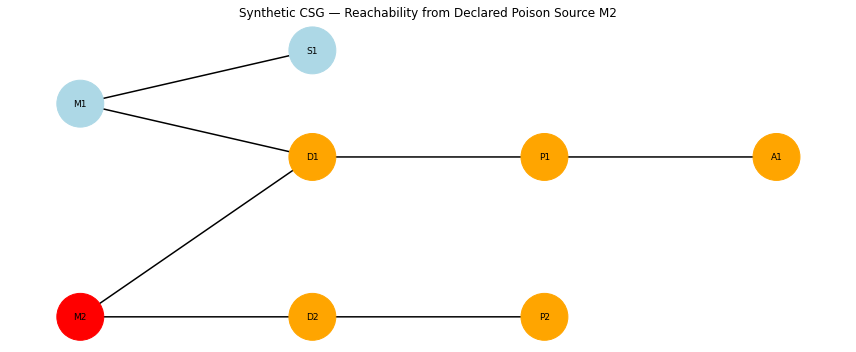

In [8]:
node_categories = {}
for node in G.nodes():
    if node == POISON_SOURCE:
        node_categories[node] = "Poison source"
    elif node in potentially_contaminated:
        node_categories[node] = "Potentially contaminated"
    else:
        node_categories[node] = "Not reachable"

category_colors = {
    "Poison source": "red",
    "Potentially contaminated": "orange",
    "Not reachable": "lightblue",
}
node_colors = [category_colors[node_categories[n]] for n in G.nodes()]

plt.figure(figsize=(12, 5))
nx.draw_networkx_edges(G, pos, arrows=True, arrowsize=18, width=1.5)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=2200)
nx.draw_networkx_labels(G, pos, font_size=9)
plt.title("Synthetic CSG — Reachability from Declared Poison Source M2")
plt.axis("off")
plt.tight_layout()
plt.show()

print("Legend:")
for category, color in category_colors.items():
    print(f"  {category}: {color}")

## 8. Validate the expected behavior with assertions

These are unit-style checks against the synthetic scenario we explicitly constructed. Passing them shows that the implementation matches this scenario; it does not validate the model against real agent traces.

In [9]:
# Expected by construction:
# M2 -> D1 -> P1 -> A1
# M2 -> D2 -> P2
# M2 has no path to M1 or S1.

assert potentially_contaminated == {"D1", "P1", "A1", "D2", "P2"}
assert "M2" not in potentially_contaminated  # descendants exclude the source
assert "S1" not in potentially_contaminated
assert "M1" not in potentially_contaminated
assert len(potentially_contaminated) == 5

print("PASS: expected descendants identified.")
print("PASS: independent branch S1 is not marked.")
print("PASS: poison source is not counted as its own descendant.")
print("All synthetic-scenario assertions passed.")

PASS: expected descendants identified.
PASS: independent branch S1 is not marked.
PASS: poison source is not counted as its own descendant.
All synthetic-scenario assertions passed.


## 9. Export artifacts for inspection

This cell writes the synthetic state table, edge list, and contamination report to CSV files. These are generated outputs from this notebook run, not an independently validated benchmark dataset.

In [10]:
state_df.to_csv("trustsr_lab01_states.csv", index=False)
edge_df.to_csv("trustsr_lab01_edges.csv", index=False)
report.to_csv("trustsr_lab01_contamination_report.csv", index=False)

print("Generated files:")
print("- trustsr_lab01_states.csv")
print("- trustsr_lab01_edges.csv")
print("- trustsr_lab01_contamination_report.csv")

Generated files:
- trustsr_lab01_states.csv
- trustsr_lab01_edges.csv
- trustsr_lab01_contamination_report.csv


## 10. Interpretation and limitations

### What this run demonstrates

1. A directed dependency graph can encode declared relationships between memory, decisions, plans, and derived states.
2. Reachability from a known poison source can identify descendants under the supplied graph.
3. A state not reachable from the source (such as `S1` in this scenario) is not flagged by this specific traversal.

### What this run does not demonstrate

- It does not detect poisoned memory; the poison source is supplied explicitly.
- It does not prove that graph edges are complete or correct.
- It does not perform selective recovery or compare against full rollback.
- It does not establish a calibrated trust score or formal soundness/completeness guarantee.
- It does not support the monograph's numerical claims about preservation, contamination, or blast radius.
- It is not a test on a real LLM agent or a production system.

### Main failure mode to investigate next

If an actual dependency edge is missing, a genuinely affected node may not be reachable from the poison source and may therefore be missed. A future lab should deliberately remove an edge and quantify the resulting false negatives.

## 11. Research record

Before citing this experiment, record:
- Notebook Git commit or version
- Date and runtime environment
- Scenario definition and assumptions
- Assertions and whether they passed
- Generated CSV artifacts
- Known limitations and any observed failures

**Reporting rule:** Describe these outputs as results from a synthetic prototype. Do not present them as measured evidence of real-world TRUSTSR effectiveness.

## Next lab

**Lab 02 — Selective Recovery vs Full Rollback:** use the same controlled scenario, define a transparent recovery policy, and compare both strategies using explicit correctness criteria. Only report metrics actually computed from the implemented experiment.